# step6_diagnostics: comparing every model on the Test day

**Owner:** P2

**Purpose:** put every model from steps 2–5 side by side on the same Test impressions and ask the questions no single notebook answers on its own: which model to use, for which readers, and at what cost to cold-article exposure and list diversity. Also check whether those answers hold up when the cold threshold changes.

**Inputs** (all on the shared Drive, written by steps 1–5):
- `data/processed/eval_candidates.parquet`, `eval_impressions.parquet`, `fit_impressions.parquet` (step 1)
- `data/scores/`: one Test score file per model (`impression_id`, `news_id`, `score`): `step2_popularity`, `content_based`, `step2_ncf_nmf_neumf`, `step3_feature_mlp_eval`, `step4_klar_eval`, `klar_mmr_<λ>`; plus the training samples `step4_klar_train_sample`, `step3_feature_mlp_train_sample`
- `data/embeddings/news_embeddings.npy` + `news_embedding_ids.parquet` (MiniLM article embeddings from `step3_features`)

**Outputs:** `outputs/results_step6.csv` (one row per model) and `outputs/step6_diagnostics/` (one `.csv` per table, the figures and `key_findings.txt`).

**Rules this notebook follows**
- **Test is scored once and nothing is chosen on it.** Every setting (threshold, list length, buckets, the MMR λ from step 5) is fixed before any score is read.
- **No numbers are typed by hand.** Every table, figure and finding is computed from the files, so a rerun updates everything. The only typed numbers are the owners' reported results in Section 0, used only to *check* that the right files were read.
- **Same metric code as every owner** (`utils/metrics.py`), so results are comparable with their notebooks.

> Runtime: Colab (high-RAM runtime recommended; no GPU needed). Run all cells top to bottom and keep the outputs. Scoring takes about 1–2 minutes per model; the analysis sections afterwards are quick.

## 0. Setup and fixed settings

In [2]:
# --- Setup: run this first, every session ---
import os, sys, subprocess, time, json
REPO_URL = "https://github.com/Fdiannz/BT4222-Project-Group-4--MIND"

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    REPO_PATH = "/content/BT4222-Project-Group-4--MIND"
    subprocess.run(["rm", "-rf", REPO_PATH])                       # fresh copy of config.py and utils/
    subprocess.run(["git", "clone", "-q", REPO_URL, REPO_PATH], check=True)
else:
    # Local run: start Jupyter inside your clone of the repo, or set MIND_REPO_DIR.
    # Set MIND_PROJECT_DIR to the folder that contains data/ and outputs/ (see config.py).
    REPO_PATH = os.environ.get("MIND_REPO_DIR", os.path.abspath("."))
sys.path.insert(0, REPO_PATH)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import config
from utils.metrics import evaluate, add_rank, topk_diversity, attach_scores, label_impression_segment

PROC = Path(config.PROCESSED_DIR)
SCORES = Path(config.SCORES_DIR)
EMB_DIR = Path(config.DATA_DIR) / "embeddings"
OUT = Path(config.OUTPUT_DIR) / "step6_diagnostics"
RESULTS_CSV = Path(config.OUTPUT_DIR) / "results_step6.csv"

# Outputs go to the shared outputs/ folder. If it is not writable (view-only access, e.g. a marker),
# fall back to a local Colab folder so the notebook still runs; nothing in the shared folder is changed.
def writable(folder):
    try:
        folder.mkdir(parents=True, exist_ok=True)
        (folder / "_write_test").write_text("ok")
        (folder / "_write_test").unlink()
        return True
    except OSError:
        return False

if not writable(OUT):
    OUT = Path("/content/step6_outputs/step6_diagnostics") if IN_COLAB else Path("step6_outputs/step6_diagnostics").resolve()
    RESULTS_CSV = OUT.parent / "results_step6.csv"
    assert writable(OUT), f"Cannot write to {OUT} either"
    print(f"Shared outputs/ is read-only for this account: saving to {OUT} instead (lost when the Colab session ends).")

for p in (PROC / "eval_candidates.parquet", PROC / "eval_impressions.parquet", SCORES):
    assert p.exists(), f"Not found: {p}. On Colab, add the shared BT4222_Project folder as a shortcut directly under My Drive."
print("Processed:", PROC, "\nScores   :", SCORES, "\nOutputs  :", OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Processed: /content/drive/MyDrive/BT4222_Project/data/processed 
Scores   : /content/drive/MyDrive/BT4222_Project/data/scores 
Outputs  : /content/drive/MyDrive/BT4222_Project/outputs/step6_diagnostics


### Why an article counts as cold below 10 earlier displays

An article is **cold** if it was shown **fewer than 10 times on earlier days** (`prior_exposure_count < 10`, step 1's `cold_article`). For the Test day (15 Nov) the counts come from 9–14 Nov: the count is fixed at the start of the day, because a model cannot learn about an article during the day it is being tested on. This is step 1's definition, so the cold flag here is exactly the one every owner used.

**Why 10, and not 1, 5 or 50?** Step 0 (Section 4) tabulated the Test day for several thresholds. Section 1 below recomputes the same table from step 1's files.

| Threshold T (cold = fewer than T earlier displays) | Cold share of Test displays | Cold-only impressions | Cold CTR ÷ average CTR |
|---|---|---|---|
| 1 (never shown before) | 5.38% | 7.35% | 1.63 |
| 5 | 11.84% | 15.23% | 1.44 |
| **10** | **17.93%** | **20.51%** | **1.31** |
| 20 | 28.29% | 28.33% | 1.16 |
| 50 | 43.53% | 43.49% | 1.13 |

- **Below 10 the cold group is too small to evaluate reliably.** At T = 1 only about 7% of impressions have only cold clicks.
- **Above 10, "cold" stops meaning rare.** At T = 50 almost half of all displays would count as cold, and those articles are clicked almost like any other (1.13× the average CTR), so the group no longer behaves differently.
- **At 10, about a fifth of impressions are cold-only, and cold articles are still clicked 1.31× as often as the average article.** They are a large, distinct group that readers want, which is the group the project is about.
- **For scale (step 1):** during 9–13 Nov the median article was shown 45 times, and a quarter of articles (5,814 of 23,291) were shown fewer than 10 times.

**10 is still a choice.** So Section 3 repeats the cold results at **5 and 20**, and any conclusion that changes with the threshold is flagged rather than reported as a finding. 10 was fixed in `config.py` before any model was scored; no threshold is chosen from Test results.

In [3]:
# --- Fixed settings (decided before any Test score is read; do not tune these on the results) ---
COLD_T = config.COLD_THRESHOLD            # 10: main cold threshold (step 1's cold_article)
COLD_T_SENS = (5, 20)                     # sensitivity checks only
THRESHOLD_TABLE = (1, 2, 5, 10, 20, 50, 100)
TOP_K = config.TOP_K                      # 10: length of the list a reader sees
SEED = config.SEED

# Test score files, one per model (names as written by each step's notebook)
MODELS = {
    "step2_popularity":       "Popularity",
    "content_based":          "Content-based",
    "step2_ncf_nmf_neumf":    "NeuMF",
    "step3_feature_mlp_eval": "Feature MLP",
    "step4_klar_eval":        "KLAR",
}
# MMR re-rankings of KLAR (step 5). score = -final rank, so AUC here is the AUC of the re-ranked order.
MMR = {f"klar_mmr_{lam}": float(lam) for lam in config.MMR_LAMBDAS}
MMR_SELECTED = 0.8      # chosen in step 5, Section 2.4, on Tune only: most category variety within 2% Tune nDCG@10 loss
# Training-impression scores (20k Fit impressions re-scored on full slates) for the train vs Test comparison
TRAIN_FILES = {"step4_klar_eval": "step4_klar_train_sample",
               "step3_feature_mlp_eval": "step3_feature_mlp_train_sample"}

# Independent diversity ruler: MiniLM sentence embeddings of title + abstract (step3_features).
# NOT the KLAR vectors, because MMR was told to make lists dissimilar in exactly that space.
DIV_EMB = (EMB_DIR / "news_embeddings.npy", EMB_DIR / "news_embedding_ids.parquet")
NEAR_DUP_SIM = 0.85     # two articles in one list with MiniLM cosine >= 0.85 count as near-duplicates

# Buckets: slate length, and user history length (same buckets as steps 3 and 4)
SLATE_BINS, SLATE_LABELS = [0, 10, 20, 30, 50, 100, np.inf], ["<=10", "11-20", "21-30", "31-50", "51-100", ">100"]
HIST_BINS, HIST_LABELS = [-1, 0, 5, 20, 50, np.inf], ["0", "1-5", "6-20", "21-50", "over 50"]
MIN_CLICK_SHARE = 0.002  # categories with under 0.2% of Test clicks are left out of the category table (too noisy)
METRICS = ["auc", "mrr", "ndcg@5", "ndcg@10"]

# Results as reported in each owner's notebook. Used ONLY to check that this notebook read the right files
# (Section 2); none of these numbers is reported from here.
OWNER = {   # key: (Tune AUC, Tune nDCG@10, Test AUC, Test nDCG@10, where it comes from)
    "step2_popularity":       (0.6076, 0.3311, 0.6293, 0.3728, "step2_popularity, Sections 2C and 3"),
    "content_based":          (None,   None,   0.5647, 0.3348, "step2_content_based (no Tune run)"),
    "step2_ncf_nmf_neumf":    (None,   0.3329, 0.5209, 0.2933, "step2_ncf_nmf, Section 3"),
    "step3_feature_mlp_eval": (0.6620, 0.3894, 0.6443, 0.3989, "step3_feature_mlp, Section 10"),
    "step4_klar_eval":        (0.6837, 0.4080, 0.6474, 0.3950, "step4_advanced_model, Section 12"),
    f"klar_mmr_{MMR_SELECTED}": (None, None,   None,   0.3881, "step5_rerank_mmr, Section 3.5 (AUC not comparable)"),
}
CHECK_TOL = 0.002        # an owner's number and ours may differ by rounding and random tie-breaks, not by more

# Readable names, one colour per model
LABEL = {"random": "Random", **MODELS,
         **{k: f"KLAR + MMR (λ={v:g})" for k, v in MMR.items()}}
SEL = LABEL[f"klar_mmr_{MMR_SELECTED}"]
MAIN = [MODELS[m] for m in MODELS]                    # the five models
FIG_MODELS = ["Random"] + MAIN + [SEL]
COLORS = {"Random": "#7f7f7f", "Popularity": "#E69F00", "Content-based": "#009E73", "NeuMF": "#56B4E9",
          "Feature MLP": "#D55E00", "KLAR": "#0072B2", SEL: "#CC79A7"}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})


def save(df, name):
    df.to_csv(OUT / f"{name}.csv")
    return df


def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def to_int_ids(s):
    # impression ids may be stored as int or as text in different files; compare them as integers
    return pd.to_numeric(s, errors="raise").astype("int64")

## 1. Load the Test day and check the score files

**What this does:** reads the Test day (15 Nov, MIND dev) from step 1: every displayed article (full slates, no sampling), its click label, its earlier display count, cold flag and category. Rows are put in a fixed order (impression, then article), so random tie-breaks in the metrics do not depend on how any file happens to be sorted.

Then every score file is checked before it is used. It must have exactly one finite score for every Test candidate, with no missing, duplicate or extra rows. If a listed file is missing, the run stops instead of quietly leaving a model out. Files in the scores folder that are not listed (for example older NRMS or NCF exports) are printed and ignored.

In [4]:
t0 = time.time()
cand = pd.read_parquet(PROC / "eval_candidates.parquet",
                       columns=["impression_id", "news_id", "label", "prior_exposure_count", "cold_article", "category"])
cand["impression_id"] = to_int_ids(cand["impression_id"])
codes, news_ids = pd.factorize(cand["news_id"].astype(str), sort=True)
NEWS = pd.Index(news_ids)                                   # article code -> news_id
cand["nid"] = codes.astype("int32")
cand = cand.drop(columns="news_id")
cand["category"] = cand["category"].astype("category")
cand["prior"] = cand.pop("prior_exposure_count").astype("int64")
cand = cand.sort_values(["impression_id", "nid"], kind="stable").reset_index(drop=True)
assert not cand.duplicated(["impression_id", "nid"]).any(), "an article appears twice in one impression"
assert cand["label"].isin([0, 1]).all()
cand["is_cold"] = (cand["prior"] < COLD_T).astype("int8")
if COLD_T == 10:
    assert (cand["is_cold"] == cand["cold_article"]).all(), "cold flag differs from step 1's cold_article"
cand = cand.drop(columns="cold_article")
CAND_IID, CAND_NID = cand["impression_id"].to_numpy(), cand["nid"].to_numpy()

# one row per impression: slate length and history length
imps = pd.read_parquet(PROC / "eval_impressions.parquet", columns=["impression_id", "history"])
imps["impression_id"] = to_int_ids(imps["impression_id"])
imps = imps.drop_duplicates("impression_id").set_index("impression_id")
imp = cand.groupby("impression_id").size().rename("slate_len").to_frame()
assert imp.index.isin(imps.index).all(), "some Test impressions are missing from eval_impressions"
hist = imps["history"].reindex(imp.index)
imp["hist_len"] = hist.fillna("").str.split().str.len().astype("int64")
imp["slate_bucket"] = pd.cut(imp["slate_len"], SLATE_BINS, labels=SLATE_LABELS)
imp["hist_bucket"] = pd.cut(imp["hist_len"], HIST_BINS, labels=HIST_LABELS)
imp["eligible"] = imp["slate_len"] > TOP_K               # step 5 re-ranks only slates with more than TOP_K candidates
del imps, hist

clicks = int(cand["label"].sum())
print(f"Test day: {len(imp):,} impressions, {len(cand):,} candidates, {clicks:,} clicks, "
      f"{cand['nid'].nunique():,} distinct articles ({time.time() - t0:.0f}s)")
print(f"Impressions with more than {TOP_K} candidates (MMR re-ranks these): {int(imp['eligible'].sum()):,}")

Test day: 376,471 impressions, 14,085,557 candidates, 574,845 clicks, 6,997 distinct articles (56s)
Impressions with more than 10 candidates (MMR re-ranks these): 282,075


In [5]:
# --- the threshold table (recomputes step 0, Section 4, from step 1's files) and the impression segments ---
pos = cand.loc[cand["label"] == 1, ["impression_id", "prior"]]
avg_ctr = cand["label"].mean()
rows, SEG = [], {}
for T in THRESHOLD_TABLE:
    cold = cand["prior"] < T
    seg = label_impression_segment(pos.assign(label=1, flag=(pos["prior"] < T).astype("int8")), "flag")
    if T in (COLD_T, *COLD_T_SENS):
        SEG[T] = seg
    share = seg.value_counts(normalize=True) * 100
    rows.append({"threshold": T, "cold_displays_%": 100 * cold.mean(),
                 "cold_clicks_%": 100 * (cold & (cand["label"] == 1)).sum() / clicks,
                 "cold_ctr_vs_average": cand.loc[cold, "label"].mean() / avg_ctr,
                 "impressions_cold_%": share.get("cold", 0), "impressions_mixed_%": share.get("mixed", 0),
                 "impressions_warm_%": share.get("warm", 0)})
thr_table = save(pd.DataFrame(rows).set_index("threshold").round(2), "cold_threshold_table")
display(thr_table)
cold_ctr = cand.loc[cand["is_cold"] == 1, "label"].mean()
warm_ctr = cand.loc[cand["is_cold"] == 0, "label"].mean()
print(f"At T={COLD_T}: cold CTR {100 * cold_ctr:.2f}% vs warm {100 * warm_ctr:.2f}%")

# Cold share of the candidates a top-10 list is chosen from (impressions with at least TOP_K candidates).
# This is the 'fair share' baseline for the cold exposure ratio in Section 3.
full_lists = imp.index[imp["slate_len"] >= TOP_K]
cand_cold = cand.groupby("impression_id")["is_cold"].mean()
CAND_COLD_SHARE = float(cand_cold.reindex(full_lists).mean())
CAND_COLD_SHARE_ELIG = float(cand_cold.reindex(imp.index[imp["eligible"]]).mean())
print(f"Cold share of candidates in impressions with >= {TOP_K} candidates: {100 * CAND_COLD_SHARE:.1f}%")

,cold_displays_%,cold_clicks_%,cold_ctr_vs_average,impressions_cold_%,impressions_mixed_%,impressions_warm_%
threshold,,,,,,
1,5.38,8.75,1.63,7.35,5.02,87.63
2,7.73,12.22,1.58,10.55,6.09,83.37
5,11.84,17.04,1.44,15.23,7.54,77.24
10,17.93,23.46,1.31,20.51,9.69,69.81
20,28.29,32.87,1.16,28.33,11.46,60.20
50,43.53,49.36,1.13,43.49,14.27,42.24
100,53.63,56.96,1.06,50.76,13.83,35.41


At T=10: cold CTR 5.34% vs warm 3.81%
Cold share of candidates in impressions with >= 10 candidates: 20.6%


In [6]:
# --- which score files exist, and are all the listed ones there? ---
on_disk = sorted(p.stem for p in SCORES.glob("*.parquet"))
needed = list(MODELS) + list(MMR) + list(TRAIN_FILES.values())
absent = [m for m in needed if m not in on_disk]
assert not absent, f"Missing score files in {SCORES}: {absent}. Rerun the step that writes them; do not drop the model silently."
ignored = [s for s in on_disk if s not in needed]
print(f"Using {len(needed)} files. Ignored (not listed in MODELS / MMR / TRAIN_FILES):", ", ".join(ignored) or "none")


def load_scores(name):
    # One score per Test candidate, aligned with the row order of `cand`. Raises on any mismatch.
    s = pd.read_parquet(SCORES / f"{name}.parquet")
    missing = {"impression_id", "news_id", "score"} - set(s.columns)
    if missing:
        raise ValueError(f"{name}: lacks columns {sorted(missing)}")
    if len(s) != len(cand):
        raise ValueError(f"{name}: {len(s):,} rows, expected {len(cand):,} (one per Test candidate)")
    iid = to_int_ids(s["impression_id"]).to_numpy()
    nid = NEWS.get_indexer(s["news_id"].astype(str))
    if (nid < 0).any():
        raise ValueError(f"{name}: {int((nid < 0).sum()):,} articles are not Test candidates. Is this a Tune or old file?")
    sc = s["score"].to_numpy(dtype=float)
    if not np.isfinite(sc).all():
        raise ValueError(f"{name}: NaN or infinite scores")
    order = np.lexsort((nid, iid))
    if not (np.array_equal(iid[order], CAND_IID) and np.array_equal(nid[order], CAND_NID)):
        raise ValueError(f"{name}: (impression, article) pairs do not match the Test candidates (duplicates or wrong rows)")
    return sc[order]

Using 13 files. Ignored (not listed in MODELS / MMR / TRAIN_FILES): klar_calibration, ncf_nmf_neumf, ncf_nmf_neumf_plus_id_masking_p0.1, nrms_mmr_0.5, nrms_mmr_0.6, nrms_mmr_0.7, nrms_mmr_0.8, nrms_mmr_0.9, nrms_mmr_1.0, step2_content_based, step2_popularity_tune, step3_feature_mlp_tune, step4_klar_tune


In [7]:
# --- independent diversity ruler: MiniLM embeddings of the Test articles ---
E_all = np.load(DIV_EMB[0], mmap_mode="r")
emb_ids = pd.read_parquet(DIV_EMB[1])["news_id"].astype(str)
assert len(emb_ids) == E_all.shape[0], "embedding ids and vectors differ in length"
rows_ = pd.Index(emb_ids).get_indexer(NEWS)
assert (rows_ >= 0).all(), f"{int((rows_ < 0).sum())} Test articles have no MiniLM embedding"
E = np.asarray(E_all[rows_], dtype=np.float32)                         # row i = article code i
E /= np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-12)
EMB = {i: E[i] for i in range(len(E))}                                 # format expected by topk_diversity
del E_all
print(f"MiniLM vectors for all {len(E):,} Test articles, dimension {E.shape[1]}")


def near_duplicate_rate(top, k=TOP_K, thr=NEAR_DUP_SIM):
    # Share of full top-k lists that contain at least one pair of articles with cosine >= thr.
    size = top.groupby("impression_id", sort=False)["nid"].transform("size")
    full = top[size == k].sort_values(["impression_id", "rank"], kind="stable")
    idx = full["nid"].to_numpy().reshape(-1, k)
    off = ~np.eye(k, dtype=bool)
    hit = np.zeros(len(idx), dtype=bool)
    for s in range(0, len(idx), 20000):
        v = E[idx[s:s + 20000]]
        hit[s:s + 20000] = ((np.einsum("nkd,njd->nkj", v, v) >= thr) & off).any((1, 2))
    return float(hit.mean())

MiniLM vectors for all 6,997 Test articles, dimension 384


## 2. Overall results: every model in one place

**What this does:** scores every model on the same 376,471 Test impressions with the shared metrics (per-impression AUC, MRR, nDCG@5 and nDCG@10, then averaged), next to a **random ranking** of the same slates. Random is the floor: a model is only useful by the amount it beats it.

**Why it is more than a copy of the owners' tables:**
- **One consistent run.** Same impressions, same code and same random reference for every model.
- **A check that the right files were read.** Each number is compared with the one in the owner's notebook. A difference larger than rounding means Step 6 is reading a wrong or old file (for example, KLAR should show AUC about 0.647).
- **Training vs Test side by side** for KLAR and the feature MLP, to show how much each overfits.

For the MMR rows, the score file holds the *re-ranked order* (score = −rank), so their AUC is the AUC of the final list. Step 5's `model_score_auc` (0.6474 at every λ) is a different quantity: the AUC of KLAR's original scores, which MMR does not change.

Everything model-specific is computed once in the next cell; the sections after it only regroup these small tables.

In [8]:
BASE = cand[["impression_id", "nid", "label", "category", "prior", "is_cold"]]
PER, CLK, DIV, DIV_ELIG, STATUS = {}, {}, {}, {}, []


def score_one(sc):
    df = BASE.assign(score=sc)
    per = evaluate(df, "score", per_impression=True).set_index("impression_id")
    dfr = add_rank(df, "score")
    clk = dfr.loc[dfr["label"] == 1, ["impression_id", "nid", "category", "prior", "rank"]]
    clk = clk.join(imp["slate_len"], on="impression_id")
    top = dfr.loc[dfr["rank"] <= TOP_K, ["impression_id", "nid", "category", "is_cold", "rank"]]
    out = []
    for t, base_share in ((top, CAND_COLD_SHARE), (top[top["impression_id"].map(imp["eligible"])], CAND_COLD_SHARE_ELIG)):
        d = topk_diversity(t, "category", EMB, news_col="nid", cold_col="is_cold", k=TOP_K)
        d["near_duplicate_rate"] = near_duplicate_rate(t)
        d["cold_exposure_ratio"] = d["cold_share"] / base_share
        out.append(d)
    return per, clk, out[0], out[1]


todo = {"random": None, **{m: m for m in MODELS}, **{m: m for m in MMR}}
rng = np.random.default_rng(SEED)
for key, fname in todo.items():
    t0 = time.time()
    sc = rng.random(len(cand)) if fname is None else load_scores(fname)
    name = LABEL[key]
    PER[name], CLK[name], DIV[name], DIV_ELIG[name] = score_one(sc)
    STATUS.append({"model": name, "file": fname or "(random, seed %d)" % SEED, "seconds": round(time.time() - t0)})
    print(f"{name:24s} AUC {PER[name]['auc'].mean():.4f}  nDCG@10 {PER[name]['ndcg@10'].mean():.4f}  ({time.time() - t0:.0f}s)")
    del sc
save(pd.DataFrame(STATUS).set_index("model"), "model_files")

Random                   AUC 0.5001  nDCG@10 0.2865  (64s)
Popularity               AUC 0.6293  nDCG@10 0.3728  (89s)
Content-based            AUC 0.5647  nDCG@10 0.3349  (100s)
NeuMF                    AUC 0.5209  nDCG@10 0.2938  (88s)
Feature MLP              AUC 0.6443  nDCG@10 0.3989  (109s)
KLAR                     AUC 0.6474  nDCG@10 0.3950  (98s)
KLAR + MMR (λ=1)         AUC 0.6474  nDCG@10 0.3950  (91s)
KLAR + MMR (λ=0.9)       AUC 0.6458  nDCG@10 0.3923  (88s)
KLAR + MMR (λ=0.8)       AUC 0.6431  nDCG@10 0.3881  (87s)
KLAR + MMR (λ=0.7)       AUC 0.6391  nDCG@10 0.3816  (87s)
KLAR + MMR (λ=0.6)       AUC 0.6332  nDCG@10 0.3726  (85s)
KLAR + MMR (λ=0.5)       AUC 0.6253  nDCG@10 0.3617  (86s)


,file,seconds
model,,
Random,"(random, seed 42)",64
Popularity,step2_popularity,89
Content-based,content_based,100
NeuMF,step2_ncf_nmf_neumf,88
Feature MLP,step3_feature_mlp_eval,109
KLAR,step4_klar_eval,98
KLAR + MMR (λ=1),klar_mmr_1.0,91
KLAR + MMR (λ=0.9),klar_mmr_0.9,88
KLAR + MMR (λ=0.8),klar_mmr_0.8,87


In [10]:
# --- overall table, and the check against each owner's notebook ---
overall = pd.DataFrame({m: per[METRICS].mean() for m, per in PER.items()}).T
overall["n_impressions"] = [len(per) for per in PER.values()]
overall = save(overall.round(4), "overall_test")
display(overall)

chk = []
for key, (tune_auc, tune_ndcg, test_auc, test_ndcg, src) in OWNER.items():
    m = LABEL[key]
    row = {"model": m, "source": src, "owner_auc": test_auc, "step6_auc": overall.loc[m, "auc"],
           "owner_ndcg@10": test_ndcg, "step6_ndcg@10": overall.loc[m, "ndcg@10"]}
    diffs = [abs(row["step6_auc"] - test_auc) if test_auc is not None else 0,
             abs(row["step6_ndcg@10"] - test_ndcg) if test_ndcg is not None else 0]
    row["match"] = "OK" if max(diffs) <= CHECK_TOL else "CHECK: wrong or old file?"
    chk.append(row)
chk = save(pd.DataFrame(chk).set_index("model"), "check_against_owner_notebooks")
display(chk)
bad = chk.index[chk["match"] != "OK"].tolist()
if bad:
    print("!" * 90 + f"\nWARNING: {bad} differ from their owners' notebooks by more than {CHECK_TOL}.\n"
          "Most likely an old score file. Do not use these rows until the owner confirms which file is current.\n" + "!" * 90)
else:
    print(f"All models match their owners' notebooks within {CHECK_TOL}: the right files were read.")

# lambda = 1 must give KLAR's ranking. The only allowed difference is the order of articles with exactly equal
# KLAR scores: step 5 and step 6 break those ties independently, and -rank has no ties, so AUC counts a tied pair
# as 0 or 1 instead of 0.5. So: differences only in impressions with tied KLAR scores, and the same overall averages.
k1 = PER[LABEL["klar_mmr_1.0"]]
kl = PER["KLAR"].reindex(k1.index)
differs = np.zeros(len(k1), dtype=bool)
for c in METRICS:
    differs |= ~np.isclose(k1[c].to_numpy(), kl[c].to_numpy(), atol=1e-9)
klar_sc = load_scores("step4_klar_eval")
sc_df = pd.DataFrame({"impression_id": CAND_IID, "score": klar_sc})
tied_imps = pd.Index(sc_df.loc[sc_df.duplicated(["impression_id", "score"], keep=False), "impression_id"].unique())
outside_ties = k1.index[differs].difference(tied_imps)
gap = max(abs(k1[c].mean() - kl[c].mean()) for c in METRICS)
print(f"Impressions where KLAR has tied scores: {len(tied_imps):,}; where klar_mmr_1.0 differs from KLAR: {int(differs.sum()):,}; "
      f"differences outside tied impressions: {len(outside_ties):,}; largest gap in the overall averages: {gap:.5f}")
assert len(outside_ties) == 0, "klar_mmr_1.0 differs from KLAR beyond score ties: step 5 was run on different KLAR scores"
assert gap < 5e-4, "klar_mmr_1.0 and KLAR differ overall by more than tie-breaking can explain"
print("OK: klar_mmr_1.0 is KLAR's ranking; the only differences are the order of articles with tied KLAR scores.")
del klar_sc, sc_df

,auc,mrr,ndcg@5,ndcg@10,n_impressions
Random,0.5001,0.2188,0.2235,0.2865,376471
Popularity,0.6293,0.2869,0.3136,0.3728,376471
Content-based,0.5647,0.2558,0.2692,0.3349,376471
NeuMF,0.5209,0.2242,0.2292,0.2938,376471
Feature MLP,0.6443,0.3068,0.3362,0.3989,376471
KLAR,0.6474,0.2987,0.3286,0.3950,376471
KLAR + MMR (λ=1),0.6474,0.2987,0.3286,0.3950,376471
KLAR + MMR (λ=0.9),0.6458,0.2973,0.3258,0.3923,376471
KLAR + MMR (λ=0.8),0.6431,0.2953,0.3215,0.3881,376471
KLAR + MMR (λ=0.7),0.6391,0.2923,0.3155,0.3816,376471


,source,owner_auc,step6_auc,owner_ndcg@10,step6_ndcg@10,match
model,,,,,,
Popularity,"step2_popularity, Sections 2C and 3",0.6293,0.6293,0.3728,0.3728,OK
Content-based,step2_content_based (no Tune run),0.5647,0.5647,0.3348,0.3349,OK
NeuMF,"step2_ncf_nmf, Section 3",0.5209,0.5209,0.2933,0.2938,OK
Feature MLP,"step3_feature_mlp, Section 10",0.6443,0.6443,0.3989,0.3989,OK
KLAR,"step4_advanced_model, Section 12",0.6474,0.6474,0.3950,0.3950,OK
KLAR + MMR (λ=0.8),"step5_rerank_mmr, Section 3.5 (AUC not compara...",NaN,0.6431,0.3881,0.3881,OK


All models match their owners' notebooks within 0.002: the right files were read.
Impressions where KLAR has tied scores: 78; where klar_mmr_1.0 differs from KLAR: 7; differences outside tied impressions: 0; largest gap in the overall averages: 0.00000
OK: klar_mmr_1.0 is KLAR's ranking; the only differences are the order of articles with tied KLAR scores.


In [11]:
# --- training vs Tune vs Test (KLAR and the feature MLP; the others have no full-slate training sample) ---
need_ids = set()
train_scores = {}
for key, f in TRAIN_FILES.items():
    s = pd.read_parquet(SCORES / f"{f}.parquet", columns=["impression_id", "news_id", "score"])
    s["impression_id"] = to_int_ids(s["impression_id"])
    s["news_id"] = s["news_id"].astype(str)
    train_scores[key] = s
    need_ids |= set(s["impression_id"].unique())

import pyarrow.parquet as pq
fit_path = PROC / "fit_impressions.parquet"
id_is_int = str(pq.read_schema(fit_path).field("impression_id").type).startswith(("int", "uint"))
ids_filter = [int(x) for x in need_ids] if id_is_int else [str(x) for x in need_ids]
fit = pd.read_parquet(fit_path, columns=["impression_id", "impressions"],
                      filters=[("impression_id", "in", ids_filter)])          # read only the sampled impressions
fit["impression_id"] = to_int_ids(fit["impression_id"])
fit = fit.drop_duplicates("impression_id")
assert fit["impression_id"].nunique() == len(need_ids), "some training-sample impressions are not in fit_impressions"
lab = fit.assign(item=fit["impressions"].str.split()).explode("item")
nl = lab["item"].str.rsplit("-", n=1)
lab = pd.DataFrame({"impression_id": lab["impression_id"].to_numpy(), "news_id": nl.str[0].to_numpy(),
                    "label": nl.str[1].astype(int).to_numpy()})
del fit

tt = []
for key, s in train_scores.items():
    labels = lab[lab["impression_id"].isin(s["impression_id"].unique())]
    tr = evaluate(attach_scores(labels, s), "score")          # raises if any training candidate lacks a score
    tune_auc, tune_ndcg = OWNER[key][:2]
    m = LABEL[key]
    tt.append({"model": m, "train_impressions": tr["n_impressions"],
               "train_auc": tr["auc"], "tune_auc (owner)": tune_auc, "test_auc": overall.loc[m, "auc"],
               "train_ndcg@10": tr["ndcg@10"], "tune_ndcg@10 (owner)": tune_ndcg, "test_ndcg@10": overall.loc[m, "ndcg@10"]})
tt = pd.DataFrame(tt).set_index("model")
tt["auc_drop_train_to_test"] = tt["train_auc"] - tt["test_auc"]
tt = save(tt.round(4), "train_tune_test")
display(tt)
print("Train = 20,000 Fit impressions (9-13 Nov) the model learned from, re-scored on full slates. "
      "Tune = 14 Nov, used to pick epochs and settings. Test = 15 Nov, scored once here.")
del lab, train_scores

,train_impressions,train_auc,tune_auc (owner),test_auc,train_ndcg@10,tune_ndcg@10 (owner),test_ndcg@10,auc_drop_train_to_test
model,,,,,,,,
KLAR,20000,0.7701,0.6837,0.6474,0.5096,0.4080,0.3950,0.1227
Feature MLP,20000,0.7052,0.6620,0.6443,0.3953,0.3894,0.3989,0.0609


Train = 20,000 Fit impressions (9-13 Nov) the model learned from, re-scored on full slates. Tune = 14 Nov, used to pick epochs and settings. Test = 15 Nov, scored once here.


## 3. Cold vs warm articles

**What the owners already showed:** cold, warm and mixed results for their own model, each against random.

**What is new here:**
1. **All models side by side, as lift over random.** Impressions are grouped by what was clicked: *cold* (every clicked article cold), *warm* (none) or *mixed*. Cold-click impressions have shorter slates (24.5 candidates on average, against 37.7 for warm; step 1), and on a short slate even a random ranking scores well. So each model is read as **its score minus random's score in the same group**.
2. **Per click, hit@10 for cold and warm clicks.**
   - *Question:* "When a reader clicked a cold article, did the model have it in its top 10?"
   - *How to read it:* compare with random's hit@10. If a model's cold hit@10 is **below random's**, it actively buries new articles.
   - Working per click avoids the blur of mixed impressions.
3. **Cold exposure ratio, all models.**
   - *Question:* "Does the top 10 show cold articles in proportion to how many were on offer?"
   - It is the cold share of the model's top-10 slots divided by the cold share of the candidates it chose from.
   - *How to read it:* **1 = fair**, about 0.7 = cold articles hidden, about 1.5 = cold articles pushed. Pushing is not automatically good: check the same model's warm results too.
4. **Thresholds 5 and 20.**
   - *Question:* "If cold were defined a little differently, would model A still beat model B on cold?"
   - *How to read it:* if the order flips between thresholds, don't claim either model is better for cold. The flips are listed automatically below.

In [12]:
def seg_table(T):
    rows = []
    for m, per in PER.items():
        s = per.index.map(SEG[T])
        for seg in ["all", "cold", "mixed", "warm"]:
            sub = per if seg == "all" else per[s == seg]
            rows.append({"model": m, "segment": seg, "n_impressions": len(sub), **sub[METRICS].mean().to_dict()})
    t = pd.DataFrame(rows).set_index(["model", "segment"])
    rnd = t.loc["Random"]
    for c in ("auc", "ndcg@10"):
        t[f"{c}_lift_over_random"] = t[c] - rnd[c].reindex(t.index.get_level_values("segment")).to_numpy()
    return t.round(4)


def click_table(T):
    rows = []
    for m, c in CLK.items():
        flag = np.where(c["prior"] < T, "cold", "warm")
        for seg in ["all", "cold", "warm"]:
            k = np.ones(len(c), bool) if seg == "all" else flag == seg
            r = c["rank"].to_numpy()[k]
            rows.append({"model": m, "clicked_article": seg, "n_clicks": int(k.sum()), "hit@5": (r <= 5).mean(),
                         "hit@10": (r <= 10).mean(), "click_rr": (1 / r).mean(),
                         "median_rank_pct": np.median(r / c["slate_len"].to_numpy()[k])})
    return pd.DataFrame(rows).set_index(["model", "clicked_article"]).round(4)


ALL_T = (COLD_T, *COLD_T_SENS)
SEGT = {T: save(seg_table(T), f"cold_warm_impressions_T{T}") for T in ALL_T}
CLKT = {T: save(click_table(T), f"cold_warm_clicks_T{T}") for T in ALL_T}

print(f"nDCG@10 by impression segment, T={COLD_T} (raw values; compare across models within a column):")
display(SEGT[COLD_T]["ndcg@10"].unstack("segment")[["all", "cold", "mixed", "warm"]].loc[FIG_MODELS])
print("nDCG@10 lift over random (model minus random, same segment):")
display(SEGT[COLD_T]["ndcg@10_lift_over_random"].unstack("segment")[["all", "cold", "mixed", "warm"]].loc[FIG_MODELS])
print(f"Per click, T={COLD_T}: hit@10 = clicked article was in the model's top 10")
display(CLKT[COLD_T]["hit@10"].unstack("clicked_article")[["all", "cold", "warm"]].loc[FIG_MODELS])

expo = pd.DataFrame({m: {"top10_cold_share": DIV[m]["cold_share"], "candidates_cold_share": round(CAND_COLD_SHARE, 4),
                         "cold_exposure_ratio": DIV[m]["cold_exposure_ratio"],
                         "hit@10_cold_clicks": CLKT[COLD_T].loc[(m, "cold"), "hit@10"],
                         "hit@10_warm_clicks": CLKT[COLD_T].loc[(m, "warm"), "hit@10"]} for m in PER}).T
expo = save(expo.astype(float).round(4), "cold_exposure")
print("Cold exposure in the top 10 (1 = cold articles shown in proportion to the slate):")
display(expo.loc[FIG_MODELS])

nDCG@10 by impression segment, T=10 (raw values; compare across models within a column):


segment,all,cold,mixed,warm
model,,,,
Random,0.2865,0.3828,0.1794,0.2731
Popularity,0.3728,0.3767,0.2465,0.3892
Content-based,0.3349,0.4665,0.2462,0.3085
NeuMF,0.2938,0.3662,0.1759,0.2889
Feature MLP,0.3989,0.5146,0.3274,0.3748
KLAR,0.3950,0.4789,0.3266,0.3799
KLAR + MMR (λ=0.8),0.3881,0.4759,0.3177,0.3720


nDCG@10 lift over random (model minus random, same segment):


segment,all,cold,mixed,warm
model,,,,
Random,0.0000,0.0000,0.0000,0.0000
Popularity,0.0863,-0.0060,0.0671,0.1161
Content-based,0.0484,0.0837,0.0668,0.0354
NeuMF,0.0073,-0.0165,-0.0035,0.0158
Feature MLP,0.1124,0.1319,0.1480,0.1018
KLAR,0.1086,0.0962,0.1472,0.1068
KLAR + MMR (λ=0.8),0.1016,0.0931,0.1383,0.0990


Per click, T=10: hit@10 = clicked article was in the model's top 10


clicked_article,all,cold,warm
model,,,
Random,0.4300,0.5134,0.4045
Popularity,0.5404,0.4979,0.5535
Content-based,0.4954,0.6107,0.4600
NeuMF,0.4417,0.4974,0.4246
Feature MLP,0.5733,0.6999,0.5345
KLAR,0.5817,0.6422,0.5632
KLAR + MMR (λ=0.8),0.5689,0.6362,0.5483


Cold exposure in the top 10 (1 = cold articles shown in proportion to the slate):


,top10_cold_share,candidates_cold_share,cold_exposure_ratio,hit@10_cold_clicks,hit@10_warm_clicks
Random,0.2056,0.2056,0.9999,0.5134,0.4045
Popularity,0.1528,0.2056,0.7431,0.4979,0.5535
Content-based,0.2331,0.2056,1.1336,0.6107,0.4600
NeuMF,0.1816,0.2056,0.8832,0.4974,0.4246
Feature MLP,0.2413,0.2056,1.1735,0.6999,0.5345
KLAR,0.2196,0.2056,1.0680,0.6422,0.5632
KLAR + MMR (λ=0.8),0.2181,0.2056,1.0607,0.6362,0.5483


In [13]:
# --- threshold sensitivity: does the order of models on cold impressions change with T? ---
sens = pd.DataFrame({f"T={T}": SEGT[T].xs("cold", level="segment")["ndcg@10_lift_over_random"] for T in sorted(ALL_T)}).loc[MAIN + [SEL]]
sens_clk = pd.DataFrame({f"T={T}": CLKT[T].xs("cold", level="clicked_article")["hit@10"] for T in sorted(ALL_T)}).loc[["Random"] + MAIN + [SEL]]
save(sens, "sensitivity_cold_ndcg_lift")
save(sens_clk, "sensitivity_cold_hit10")
print("Cold impressions: nDCG@10 lift over random, by threshold")
display(sens)
print("Cold clicks: hit@10, by threshold")
display(sens_clk)

FLIPS = []
for i, a in enumerate(MAIN):
    for b in MAIN[i + 1:]:
        signs = np.sign(sens.loc[a] - sens.loc[b])
        if (signs > 0).any() and (signs < 0).any():
            FLIPS.append(f"{a} vs {b}: " + ", ".join(f"{t} {'>' if v > 0 else '<'}" for t, v in signs.items()))
print("Pairs whose order on cold impressions flips with the threshold (do not claim either is better for cold):")
print("\n".join("  - " + f for f in FLIPS) if FLIPS else "  none: the cold ordering of the five models is the same at every threshold")

Cold impressions: nDCG@10 lift over random, by threshold


,T=5,T=10,T=20
model,,,
Popularity,-0.0054,-0.0060,-0.0121
Content-based,0.0613,0.0837,0.0702
NeuMF,-0.0140,-0.0165,-0.0165
Feature MLP,0.1261,0.1319,0.1400
KLAR,0.1157,0.0962,0.0990
KLAR + MMR (λ=0.8),0.1111,0.0931,0.0965


Cold clicks: hit@10, by threshold


,T=5,T=10,T=20
model,,,
Random,0.5515,0.5134,0.4693
Popularity,0.5208,0.4979,0.4513
Content-based,0.6137,0.6107,0.5526
NeuMF,0.5374,0.4974,0.4521
Feature MLP,0.7157,0.6999,0.6665
KLAR,0.7019,0.6422,0.6009
KLAR + MMR (λ=0.8),0.6930,0.6362,0.5956


Pairs whose order on cold impressions flips with the threshold (do not claim either is better for cold):
  none: the cold ordering of the five models is the same at every threshold


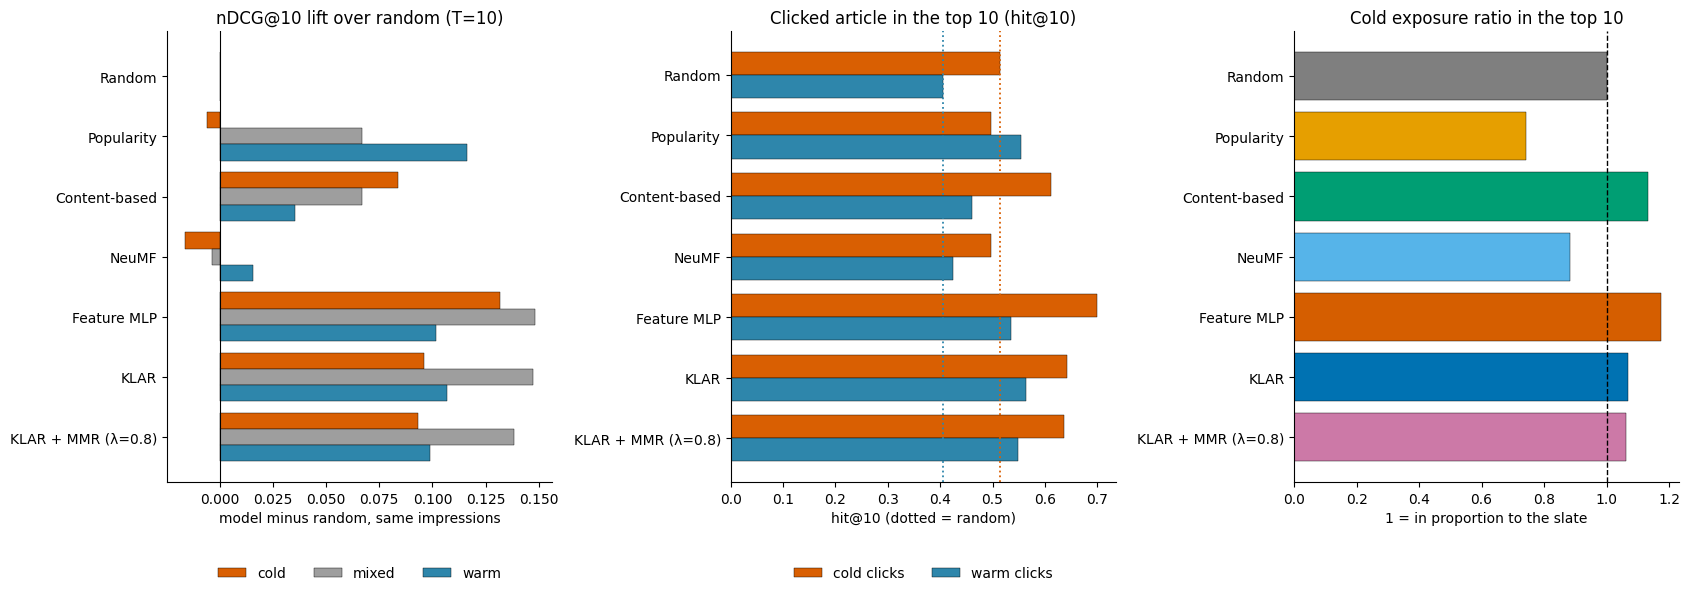

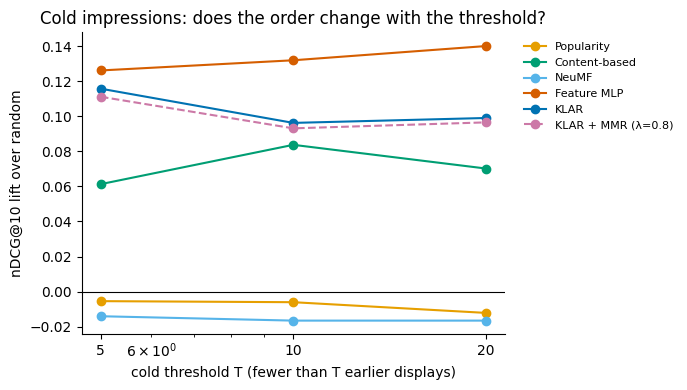

In [14]:
ms = FIG_MODELS
lift = SEGT[COLD_T]["ndcg@10_lift_over_random"].unstack("segment").loc[ms]
hit = CLKT[COLD_T]["hit@10"].unstack("clicked_article").loc[ms]
fig, axes = plt.subplots(1, 3, figsize=(17, 0.5 * len(ms) + 2.6))
y = np.arange(len(ms))

for j, (seg, col) in enumerate(zip(["cold", "mixed", "warm"], ["#d95f02", "#9e9e9e", "#2e86ab"])):
    axes[0].barh(y + (j - 1) * 0.27, lift[seg], height=0.27, color=col, edgecolor="black", lw=.3, label=seg)
axes[0].axvline(0, color="black", lw=.8)
axes[0].set(title=f"nDCG@10 lift over random (T={COLD_T})", xlabel="model minus random, same impressions")

for j, (seg, col) in enumerate(zip(["cold", "warm"], ["#d95f02", "#2e86ab"])):
    axes[1].barh(y + (j - .5) * 0.38, hit[seg], height=0.38, color=col, edgecolor="black", lw=.3, label=f"{seg} clicks")
    axes[1].axvline(hit.loc["Random", seg], color=col, ls=":", lw=1.3)
axes[1].set(title="Clicked article in the top 10 (hit@10)", xlabel="hit@10 (dotted = random)")

axes[2].barh(y, expo.loc[ms, "cold_exposure_ratio"], color=[COLORS[m] for m in ms], edgecolor="black", lw=.3)
axes[2].axvline(1, color="black", ls="--", lw=1)
axes[2].set(title="Cold exposure ratio in the top 10", xlabel="1 = in proportion to the slate")
for ax in axes:
    ax.set_yticks(y, ms)
    ax.invert_yaxis()
for ax in axes[:2]:
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False)
savefig("fig_cold_warm")

fig, ax = plt.subplots(figsize=(7, 4))
xs = [int(c.split("=")[1]) for c in sens.columns]
for m in sens.index:
    ax.plot(xs, sens.loc[m], marker="o", color=COLORS.get(m, "#444"), ls="--" if m == SEL else "-", label=m)
ax.axhline(0, color="black", lw=.8)
ax.set(xscale="log", xticks=xs, xticklabels=xs, xlabel="cold threshold T (fewer than T earlier displays)",
       ylabel="nDCG@10 lift over random", title="Cold impressions: does the order change with the threshold?")
ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
savefig("fig_cold_threshold_sensitivity")

## 4. Diversity and the MMR trade-off

**What step 5 already showed:** MMR at λ = 0.8 adds category variety for a small relevance cost, with similarity measured in **KLAR's own article vectors**.

**What is new here:**
1. **An independent ruler.** Judging MMR with KLAR's vectors is like marking an exam with the answer key: MMR was told to make lists dissimilar in exactly that space, so it is bound to look good there. Here similarity is measured with **MiniLM sentence embeddings** of each article's title and abstract (from `step3_features`), which MMR never saw. This shows whether lists *really* became more varied.
   - **Intra-list similarity:** average cosine similarity between the 10 articles of a list. Lower = more varied.
   - **Near-duplicate rate:** share of lists containing at least one pair of almost identical articles (cosine ≥ 0.85).
   - **Distinct categories:** how many different categories appear in the 10.
2. **All models compared, not only KLAR and MMR**, so the diversity of a model's lists can be weighed against its relevance.
3. **The full λ sweep**, showing how much relevance each step of variety costs and what happens to cold exposure. MMR has no term for cold articles, so it is not expected to raise their exposure.

**Two populations, both labelled.** "All lists" = every impression with at least 10 candidates. "Eligible" = impressions with **more than** 10 candidates, the only ones MMR can re-rank (step 5's population). On slates of 10 or fewer, MMR's list equals KLAR's.

**One caveat:** MiniLM is also an input to the feature MLP (its user × article similarity feature). The ruler is independent of MMR and KLAR, but not fully of the MLP.

In [15]:
def div_table(src):
    t = pd.DataFrame(src).T[["unique_categories", "intra_list_sim", "near_duplicate_rate", "cold_share",
                             "cold_exposure_ratio", "n_lists"]].astype(float)
    return t.rename(columns={"unique_categories": "distinct_categories", "intra_list_sim": "intra_list_sim_minilm",
                             "cold_share": "top10_cold_share"})


div_all = div_table(DIV).join(overall[["ndcg@10"]])
div_elig = div_table(DIV_ELIG).join(pd.DataFrame({m: {"ndcg@10_eligible": per.loc[imp.index[imp["eligible"]].intersection(per.index), "ndcg@10"].mean()}
                                                  for m, per in PER.items()}).T)
save(div_all.round(4), "diversity_all_lists")
save(div_elig.round(4), "diversity_eligible_lists")
print(f"Top-{TOP_K} lists, all impressions with at least {TOP_K} candidates:")
display(div_all.loc[FIG_MODELS].round(4))

sweep_keys = sorted(MMR, key=lambda k: -MMR[k])
sweep = pd.DataFrame({LABEL[k]: {"lambda": MMR[k], "ndcg@10_all": overall.loc[LABEL[k], "ndcg@10"],
                                 "ndcg@10_eligible": div_elig.loc[LABEL[k], "ndcg@10_eligible"],
                                 "distinct_categories": div_elig.loc[LABEL[k], "distinct_categories"],
                                 "intra_list_sim_minilm": div_elig.loc[LABEL[k], "intra_list_sim_minilm"],
                                 "near_duplicate_rate": div_elig.loc[LABEL[k], "near_duplicate_rate"],
                                 "top10_cold_share": div_elig.loc[LABEL[k], "top10_cold_share"]} for k in sweep_keys}).T
ref = sweep.iloc[0]
sweep["ndcg@10_eligible_change_%"] = 100 * (sweep["ndcg@10_eligible"] / ref["ndcg@10_eligible"] - 1)
sweep = save(sweep.round(4), "mmr_sweep_eligible")
print(f"MMR sweep on the {int(imp['eligible'].sum()):,} eligible impressions (λ = 1 is KLAR; λ = {MMR_SELECTED:g} chosen on Tune in step 5):")
display(sweep)

Top-10 lists, all impressions with at least 10 candidates:


,distinct_categories,intra_list_sim_minilm,near_duplicate_rate,top10_cold_share,cold_exposure_ratio,n_lists,ndcg@10
Random,6.4948,0.0639,0.0003,0.2056,0.9999,294491.0,0.2865
Popularity,6.0793,0.0766,0.0001,0.1528,0.7431,294491.0,0.3728
Content-based,6.2826,0.0848,0.0016,0.2331,1.1336,294491.0,0.3349
NeuMF,6.5342,0.0692,0.0002,0.1816,0.8832,294491.0,0.2938
Feature MLP,5.4958,0.1066,0.0022,0.2413,1.1735,294491.0,0.3989
KLAR,5.6319,0.0880,0.0012,0.2196,1.0680,294491.0,0.3950
KLAR + MMR (λ=0.8),6.1118,0.0803,0.0007,0.2181,1.0607,294491.0,0.3881


MMR sweep on the 282,075 eligible impressions (λ = 1 is KLAR; λ = 0.8 chosen on Tune in step 5):


,lambda,ndcg@10_all,ndcg@10_eligible,distinct_categories,intra_list_sim_minilm,near_duplicate_rate,top10_cold_share,ndcg@10_eligible_change_%
KLAR + MMR (λ=1),1.0,0.3950,0.3079,5.6037,0.0893,0.0012,0.2159,0.0000
KLAR + MMR (λ=0.9),0.9,0.3923,0.3042,5.8295,0.0857,0.0010,0.2152,-1.2010
KLAR + MMR (λ=0.8),0.8,0.3881,0.2986,6.1048,0.0812,0.0007,0.2143,-3.0236
KLAR + MMR (λ=0.7),0.7,0.3816,0.2900,6.4353,0.0756,0.0004,0.2125,-5.8092
KLAR + MMR (λ=0.6),0.6,0.3726,0.2779,6.8081,0.0694,0.0002,0.2089,-9.7398
KLAR + MMR (λ=0.5),0.5,0.3617,0.2634,7.1781,0.0637,0.0001,0.2033,-14.4626


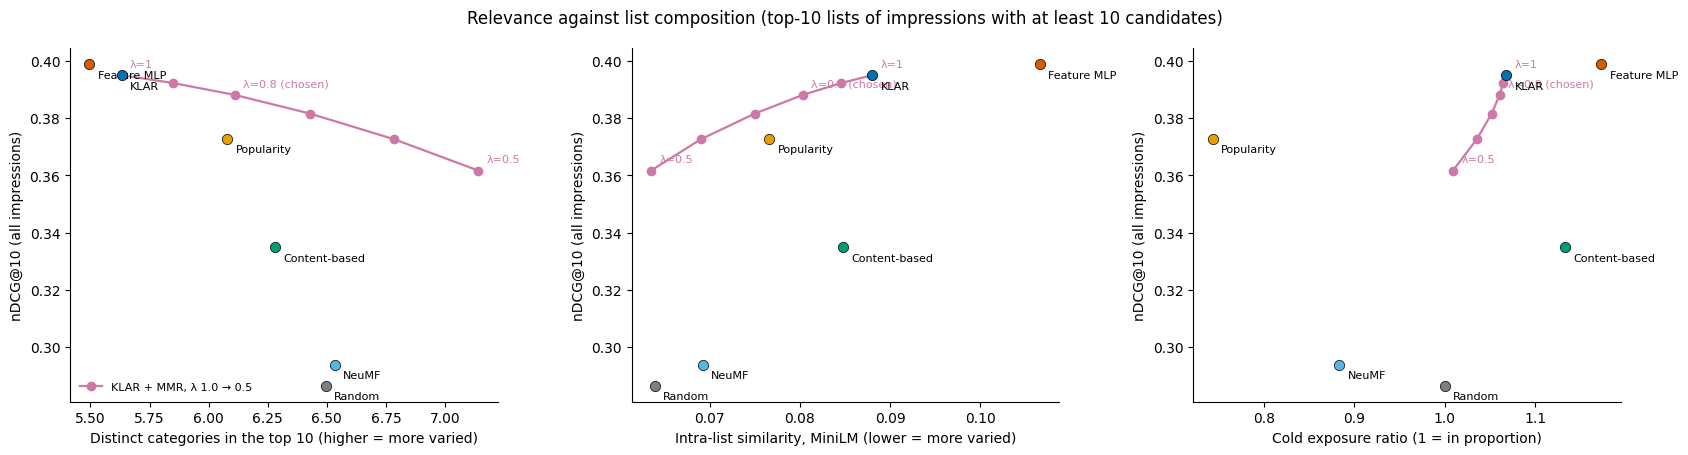

In [16]:
others = [m for m in FIG_MODELS if m != SEL]
mm = [LABEL[k] for k in sweep_keys]
panels = [("distinct_categories", "Distinct categories in the top 10 (higher = more varied)"),
          ("intra_list_sim_minilm", "Intra-list similarity, MiniLM (lower = more varied)"),
          ("cold_exposure_ratio", "Cold exposure ratio (1 = in proportion)")]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (col, xlab) in zip(axes, panels):
    ax.plot(div_all.loc[mm, col], div_all.loc[mm, "ndcg@10"], color=COLORS[SEL], marker="o", lw=1.6,
            label="KLAR + MMR, λ 1.0 → 0.5")
    for m in mm:
        lam = MMR[[k for k in MMR if LABEL[k] == m][0]]
        if lam in (1.0, MMR_SELECTED, min(MMR.values())):
            ax.annotate(f"λ={lam:g}" + (" (chosen)" if lam == MMR_SELECTED else ""),
                        (div_all.loc[m, col], div_all.loc[m, "ndcg@10"]), fontsize=8, color=COLORS[SEL],
                        xytext=(6, 6), textcoords="offset points")
    for m in others:
        ax.scatter(div_all.loc[m, col], div_all.loc[m, "ndcg@10"], s=55, color=COLORS[m], edgecolor="black", lw=.5, zorder=3)
        ax.annotate(m, (div_all.loc[m, col], div_all.loc[m, "ndcg@10"]), fontsize=8, xytext=(6, -10), textcoords="offset points")
    ax.set(xlabel=xlab, ylabel="nDCG@10 (all impressions)")
axes[0].legend(fontsize=8, frameon=False, loc="lower left")
fig.suptitle(f"Relevance against list composition (top-{TOP_K} lists of impressions with at least {TOP_K} candidates)")
savefig("fig_diversity_tradeoff")

## 5. Breakdowns: slate length, user history and category

**What the owners already showed:** KLAR and the feature MLP each broke their own results down by history length. Nobody broke results down by slate length or category, and nobody compared all models on these.

**What is new here:**
1. **Slate length** (how many articles the impression showed).
   - *Question:* "Does a model's advantage hold on long lists, where finding the clicked article is hard?"
   - *How to read it:* always against random **in the same bucket**. Short slates are easy for every model, so raw scores fall as slates get longer for everyone; the lift over random is what the model adds.
2. **User history length, all models** (how many articles the user had clicked before).
   - *Question:* "For readers with few past clicks, is a simple popularity ranking better than personalisation?"
   - *How to read it:* a personalised model needs history to work with. If Popularity wins for light users and a personalised model wins for heavy users, that is a business insight: show popular articles to new readers and switch to personalisation as their history grows. 0 clicks is the *user* cold start, separate from the article cold start.
3. **Category.**
   - *Question:* "Which topics does each model neglect?"
   - *How to read it:* hit@10 per category of the clicked article. A model can look strong overall by doing well on the two biggest categories while failing on smaller ones (for example travel).

Share of impressions per slate bucket (%): {'<=10': 25.1, '11-20': 21.2, '21-30': 13.2, '31-50': 15.4, '51-100': 17.0, '>100': 8.2}


nDCG@10 lift,<=10,11-20,21-30,31-50,51-100,>100
model,,,,,,
Random,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Popularity,0.0535,0.1092,0.1152,0.0987,0.0798,0.0715
Content-based,0.0221,0.0513,0.0615,0.0641,0.0586,0.0495
NeuMF,0.0044,-0.0072,0.0141,0.0117,0.0154,0.0176
Feature MLP,0.0738,0.1130,0.1427,0.1454,0.1228,0.0971
KLAR,0.0504,0.1116,0.1507,0.1465,0.1252,0.1052
KLAR + MMR (λ=0.8),0.0504,0.1037,0.1401,0.1364,0.1153,0.0970


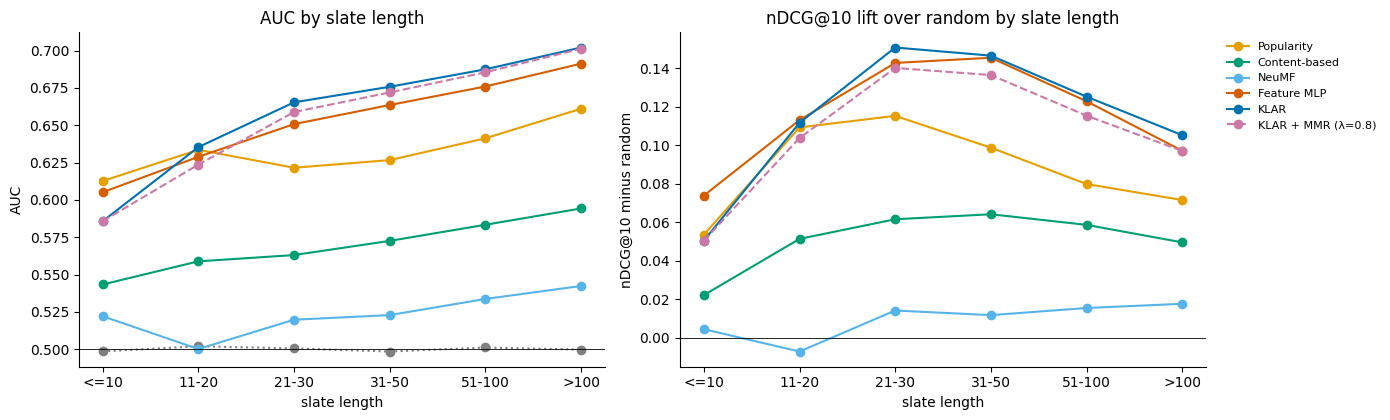

In [17]:
def bucket_table(col, labels):
    rows = []
    for m, per in PER.items():
        g = per.join(imp[[col]]).groupby(col, observed=False)
        t = g[METRICS].mean()
        t["n_impressions"] = g.size()
        t["model"] = m
        rows.append(t.reset_index())
    t = pd.concat(rows).set_index(["model", col])
    rnd = t.loc["Random"]
    t["ndcg@10_lift_over_random"] = t["ndcg@10"] - rnd["ndcg@10"].reindex(t.index.get_level_values(col)).to_numpy()
    return t.round(4)


def line_fig(tbl, col, labels, xlabel, name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
    for m in FIG_MODELS:
        s = tbl.loc[m]
        ls = ":" if m == "Random" else ("--" if m == SEL else "-")
        axes[0].plot(labels, s["auc"].reindex(labels), marker="o", color=COLORS[m], ls=ls, label=m)
        if m != "Random":
            axes[1].plot(labels, s["ndcg@10_lift_over_random"].reindex(labels), marker="o", color=COLORS[m], ls=ls, label=m)
    axes[0].axhline(0.5, color="black", lw=.6)
    axes[1].axhline(0, color="black", lw=.6)
    axes[0].set(xlabel=xlabel, ylabel="AUC", title=f"AUC by {xlabel}")
    axes[1].set(xlabel=xlabel, ylabel="nDCG@10 minus random", title=f"nDCG@10 lift over random by {xlabel}")
    axes[1].legend(fontsize=8, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
    savefig(name)


slate_t = save(bucket_table("slate_bucket", SLATE_LABELS), "by_slate_length")
print("Share of impressions per slate bucket (%):",
      (imp["slate_bucket"].value_counts(normalize=True).reindex(SLATE_LABELS) * 100).round(1).to_dict())
display(slate_t["ndcg@10_lift_over_random"].unstack("slate_bucket")[SLATE_LABELS].loc[FIG_MODELS].rename_axis(columns="nDCG@10 lift"))
line_fig(slate_t, "slate_bucket", SLATE_LABELS, "slate length", "fig_slate_length")

Share of impressions per history bucket (%): {'0': 3.0, '1-5': 14.7, '6-20': 34.9, '21-50': 27.5, 'over 50': 19.9}


nDCG@10,0,1-5,6-20,21-50,over 50
model,,,,,
Random,0.2872,0.3294,0.2971,0.2711,0.2574
Popularity,0.3686,0.4187,0.3878,0.3583,0.3335
Content-based,0.2873,0.3591,0.3430,0.3285,0.3186
NeuMF,0.2925,0.3405,0.3064,0.2784,0.2589
Feature MLP,0.3139,0.4052,0.4057,0.3992,0.3949
KLAR,0.3132,0.3928,0.3984,0.4017,0.3940
KLAR + MMR (λ=0.8),0.3072,0.3863,0.3917,0.3943,0.3867


AUC,0,1-5,6-20,21-50,over 50
model,,,,,
Random,0.4990,0.5000,0.5009,0.4992,0.5002
Popularity,0.6230,0.6350,0.6350,0.6291,0.6162
Content-based,0.5000,0.5400,0.5612,0.5767,0.5823
NeuMF,0.5173,0.5253,0.5216,0.5192,0.5193
Feature MLP,0.5405,0.5994,0.6402,0.6645,0.6721
KLAR,0.5570,0.5948,0.6398,0.6724,0.6785
KLAR + MMR (λ=0.8),0.5527,0.5897,0.6351,0.6683,0.6753


Best of the five models per history bucket (nDCG@10): {'0': 'Popularity', '1-5': 'Popularity', '6-20': 'Feature MLP', '21-50': 'KLAR', 'over 50': 'Feature MLP'}


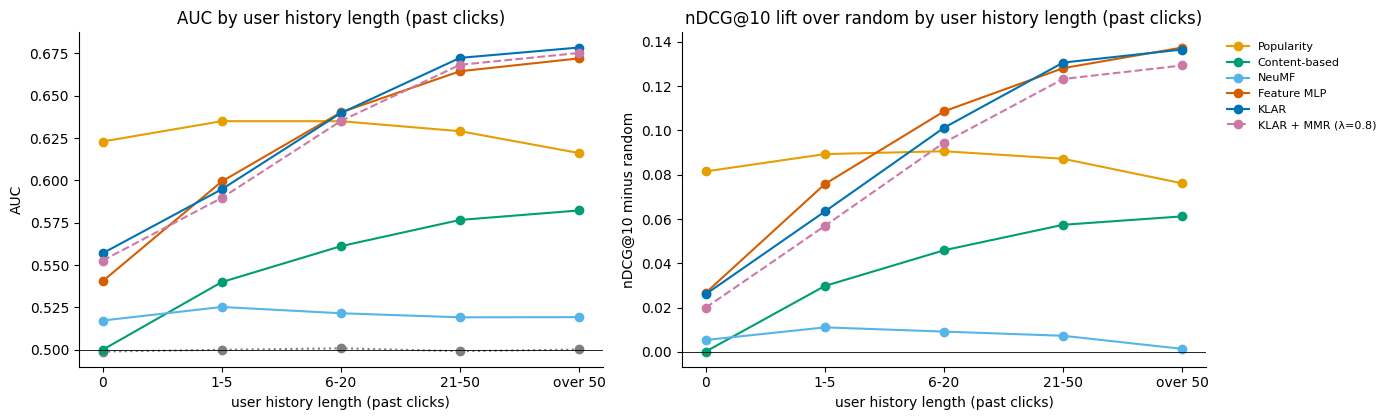

In [18]:
hist_t = save(bucket_table("hist_bucket", HIST_LABELS), "by_history_length")
print("Share of impressions per history bucket (%):",
      (imp["hist_bucket"].value_counts(normalize=True).reindex(HIST_LABELS) * 100).round(1).to_dict())
display(hist_t["ndcg@10"].unstack("hist_bucket")[HIST_LABELS].loc[FIG_MODELS].rename_axis(columns="nDCG@10"))
display(hist_t["auc"].unstack("hist_bucket")[HIST_LABELS].loc[FIG_MODELS].rename_axis(columns="AUC"))
best_per_bucket = hist_t["ndcg@10"].unstack("hist_bucket")[HIST_LABELS].loc[MAIN].idxmax()
print("Best of the five models per history bucket (nDCG@10):", best_per_bucket.to_dict())
line_fig(hist_t, "hist_bucket", HIST_LABELS, "user history length (past clicks)", "fig_history_length")

,n_clicks,Random,Popularity,Content-based,NeuMF,Feature MLP,KLAR,KLAR + MMR (λ=0.8)
category,,,,,,,,
sports,133456,0.498,0.732,0.443,0.479,0.653,0.697,0.651
news,133378,0.458,0.552,0.554,0.443,0.635,0.563,0.548
lifestyle,97119,0.498,0.601,0.599,0.537,0.622,0.684,0.678
foodanddrink,34821,0.384,0.512,0.541,0.398,0.536,0.419,0.414
tv,28678,0.375,0.630,0.421,0.369,0.576,0.553,0.553
health,23127,0.227,0.247,0.357,0.408,0.330,0.418,0.425
finance,21099,0.344,0.199,0.421,0.339,0.473,0.387,0.398
music,19440,0.484,0.377,0.553,0.523,0.676,0.588,0.620
movies,17806,0.365,0.160,0.587,0.306,0.509,0.437,0.457


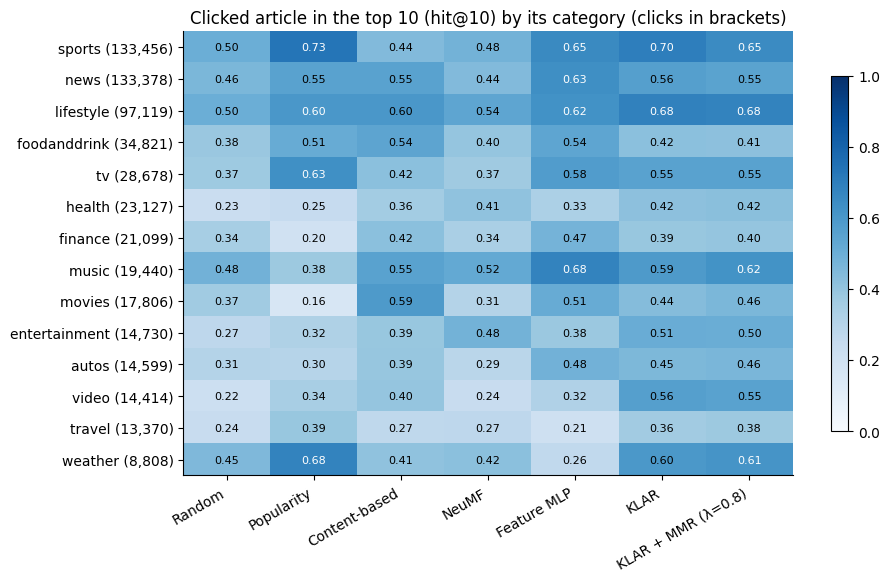

In [19]:
frames = []
for m, c in CLK.items():
    g = c.assign(rr=1 / c["rank"], hit10=c["rank"] <= TOP_K).groupby("category", observed=True).agg(
        n_clicks=("rr", "size"), hit10=("hit10", "mean"), click_rr=("rr", "mean"))
    frames.append(g.assign(model=m).reset_index())
cat_long = pd.concat(frames)
n_cat = cat_long.groupby("category", observed=True)["n_clicks"].first()
keep = n_cat[n_cat >= MIN_CLICK_SHARE * clicks].sort_values(ascending=False).index
cat_hit = cat_long.pivot(index="category", columns="model", values="hit10").loc[keep, FIG_MODELS]
cat_rr = cat_long.pivot(index="category", columns="model", values="click_rr").loc[keep, FIG_MODELS]
save(n_cat.loc[keep].rename("n_clicks").to_frame().join(cat_hit).round(4), "category_hit10")
save(n_cat.loc[keep].rename("n_clicks").to_frame().join(cat_rr).round(4), "category_click_rr")
display(n_cat.loc[keep].rename("n_clicks").to_frame().join(cat_hit.round(3)))

fig, ax = plt.subplots(figsize=(1.6 + 1.15 * cat_hit.shape[1], 0.6 + 0.38 * len(cat_hit)))
im = ax.imshow(cat_hit.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(cat_hit.shape[1]), cat_hit.columns, rotation=30, ha="right")
ax.set_yticks(range(len(cat_hit)), [f"{c} ({n:,})" for c, n in zip(cat_hit.index, n_cat.loc[keep])])
for i in range(cat_hit.shape[0]):
    for j in range(cat_hit.shape[1]):
        v = cat_hit.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > .6 else "black")
ax.set_title("Clicked article in the top 10 (hit@10) by its category (clicks in brackets)")
fig.colorbar(im, ax=ax, shrink=.8)
savefig("fig_category_hit10")

## 6. Results file and key findings

**What this does:** one row per model with every headline number (`results_step6.csv`), and the key findings written as sentences **filled in from the tables above**, so they update on every rerun. Nothing in this section is typed by hand.

**Before a finding goes into the report:** check it against the table it came from (the section is named in brackets) and rewrite it in your own words. The generated sentences state what the numbers show; they do not explain why.

In [20]:
S = overall.copy()
seg10 = SEGT[COLD_T]
for seg in ("cold", "mixed", "warm"):
    S[f"ndcg@10_{seg}"] = seg10.xs(seg, level="segment")["ndcg@10"]
    S[f"ndcg@10_{seg}_lift_over_random"] = seg10.xs(seg, level="segment")["ndcg@10_lift_over_random"]
S = S.join(expo[["hit@10_cold_clicks", "hit@10_warm_clicks", "top10_cold_share", "cold_exposure_ratio"]])
S = S.join(div_all[["distinct_categories", "intra_list_sim_minilm", "near_duplicate_rate"]])
S = S.join(tt[["train_auc", "train_ndcg@10"]])
S.index.name = "model"
S = S.round(4)
S.to_csv(RESULTS_CSV)
print("Saved:", RESULTS_CSV)
display(S.loc[FIG_MODELS + [m for m in S.index if m not in FIG_MODELS]].T)

Saved: /content/drive/MyDrive/BT4222_Project/outputs/results_step6.csv


model,Random,Popularity,Content-based,NeuMF,Feature MLP,KLAR,KLAR + MMR (λ=0.8),KLAR + MMR (λ=1),KLAR + MMR (λ=0.9),KLAR + MMR (λ=0.7),KLAR + MMR (λ=0.6),KLAR + MMR (λ=0.5)
auc,0.5001,0.6293,0.5647,0.5209,0.6443,0.6474,0.6431,0.6474,0.6458,0.6391,0.6332,0.6253
mrr,0.2188,0.2869,0.2558,0.2242,0.3068,0.2987,0.2953,0.2987,0.2973,0.2923,0.2886,0.2841
ndcg@5,0.2235,0.3136,0.2692,0.2292,0.3362,0.3286,0.3215,0.3286,0.3258,0.3155,0.3080,0.2999
ndcg@10,0.2865,0.3728,0.3349,0.2938,0.3989,0.3950,0.3881,0.3950,0.3923,0.3816,0.3726,0.3617
n_impressions,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000,376471.0000
ndcg@10_cold,0.3828,0.3767,0.4665,0.3662,0.5146,0.4789,0.4759,0.4789,0.4776,0.4723,0.4671,0.4601
ndcg@10_cold_lift_over_random,0.0000,-0.0060,0.0837,-0.0165,0.1319,0.0962,0.0931,0.0962,0.0948,0.0896,0.0843,0.0773
ndcg@10_mixed,0.1794,0.2465,0.2462,0.1759,0.3274,0.3266,0.3177,0.3266,0.3232,0.3087,0.2953,0.2787
ndcg@10_mixed_lift_over_random,0.0000,0.0671,0.0668,-0.0035,0.1480,0.1472,0.1383,0.1472,0.1438,0.1292,0.1159,0.0992
ndcg@10_warm,0.2731,0.3892,0.3085,0.2889,0.3748,0.3799,0.3720,0.3799,0.3768,0.3651,0.3556,0.3443


In [21]:
o = overall.loc[MAIN]
rnd = overall.loc["Random"]
F = []

b_ndcg, b_auc = o["ndcg@10"].idxmax(), o["auc"].idxmax()
if b_ndcg == b_auc:
    F.append(f"Relevance (Section 2): {b_ndcg} is best on both nDCG@10 ({o.loc[b_ndcg, 'ndcg@10']:.4f}) and AUC "
             f"({o.loc[b_auc, 'auc']:.4f}); a random ranking gets {rnd['ndcg@10']:.4f} and {rnd['auc']:.4f}.")
else:
    F.append(f"Relevance (Section 2): {b_ndcg} has the highest nDCG@10 ({o.loc[b_ndcg, 'ndcg@10']:.4f}, vs {o.loc[b_auc, 'ndcg@10']:.4f} "
             f"for {b_auc}) and {b_auc} the highest AUC ({o.loc[b_auc, 'auc']:.4f}, vs {o.loc[b_ndcg, 'auc']:.4f} for {b_ndcg}); "
             f"a random ranking gets {rnd['ndcg@10']:.4f} and {rnd['auc']:.4f}. The two metrics disagree on the best model, "
             f"so the report should quote both.")
F.append(f"Relevance (Section 2): KLAR AUC {o.loc['KLAR', 'auc']:.4f} vs Popularity {o.loc['Popularity', 'auc']:.4f} "
         f"({'higher' if o.loc['KLAR', 'auc'] > o.loc['Popularity', 'auc'] else 'not higher'}); "
         f"nDCG@10 {o.loc['KLAR', 'ndcg@10']:.4f} vs {o.loc['Popularity', 'ndcg@10']:.4f}.")
F.append(f"ID-only baseline (Section 2-3): NeuMF reaches nDCG@10 {o.loc['NeuMF', 'ndcg@10']:.4f} (random {rnd['ndcg@10']:.4f}); "
         f"on cold impressions its lift over random is {seg10.loc[('NeuMF', 'cold'), 'ndcg@10_lift_over_random']:+.4f}.")

r = thr_table.loc[COLD_T]
F.append(f"Cold articles (Section 1): at T={COLD_T} they are {r['cold_displays_%']:.1f}% of Test displays but {r['cold_clicks_%']:.1f}% "
         f"of clicks (CTR {100 * cold_ctr:.2f}% vs {100 * warm_ctr:.2f}% for warm).")

h_r = expo.loc["Random", "hit@10_cold_clicks"]
below = [m for m in MAIN if expo.loc[m, "hit@10_cold_clicks"] < h_r]
F.append(f"Cold clicks (Section 3): random puts {100 * h_r:.1f}% of cold-article clicks in its top 10. "
         + ("; ".join(f"{m} {100 * expo.loc[m, 'hit@10_cold_clicks']:.1f}%" for m in MAIN)) + ". "
         + (f"Below random: {', '.join(below)}." if below else "Every model is above random."))
lo, hi = expo.loc[MAIN, "cold_exposure_ratio"].idxmin(), expo.loc[MAIN, "cold_exposure_ratio"].idxmax()
F.append(f"Cold exposure (Section 3): the ratio ranges from {expo.loc[lo, 'cold_exposure_ratio']:.2f} ({lo}) to "
         f"{expo.loc[hi, 'cold_exposure_ratio']:.2f} ({hi}); 1 = in proportion. {hi}'s warm-impression nDCG@10 lift over random is "
         f"{seg10.loc[(hi, 'warm'), 'ndcg@10_lift_over_random']:+.4f}, so check whether its cold gain costs warm relevance.")
F.append("Threshold (Section 3): " + ("; ".join(FLIPS) + " (order flips with the threshold: no cold claim for these pairs)."
                                       if FLIPS else "the order of the five models on cold impressions is the same at T = 5, 10 and 20."))

k1, ks = sweep.iloc[0], sweep.loc[SEL]
F.append(f"MMR (Section 4, {int(imp['eligible'].sum()):,} eligible impressions): λ={MMR_SELECTED:g} changes nDCG@10 by "
         f"{ks['ndcg@10_eligible_change_%']:+.1f}% ({k1['ndcg@10_eligible']:.4f} → {ks['ndcg@10_eligible']:.4f}), distinct categories "
         f"{k1['distinct_categories']:.2f} → {ks['distinct_categories']:.2f}, MiniLM intra-list similarity {k1['intra_list_sim_minilm']:.4f} → "
         f"{ks['intra_list_sim_minilm']:.4f}, cold share of the top 10 {k1['top10_cold_share']:.4f} → {ks['top10_cold_share']:.4f}. "
         f"On all impressions nDCG@10 goes {overall.loc[LABEL['klar_mmr_1.0'], 'ndcg@10']:.4f} → {overall.loc[SEL, 'ndcg@10']:.4f}.")

hn = hist_t["ndcg@10"].unstack("hist_bucket")[HIST_LABELS]
pop_wins = [b for b in HIST_LABELS if hn.loc["Popularity", b] >= hn.loc[MAIN, b].max()]
F.append("History length (Section 5): best model per bucket: " + ", ".join(f"{b}: {best_per_bucket[b]}" for b in HIST_LABELS) + ". "
         + (f"Popularity is best for {', '.join(pop_wins)} past clicks." if pop_wins else "Popularity is not best in any bucket."))
sl = slate_t["ndcg@10_lift_over_random"].unstack("slate_bucket")[SLATE_LABELS].loc[MAIN]
F.append("Slate length (Section 5): best lift over random per bucket: " + ", ".join(f"{b}: {sl[b].idxmax()}" for b in SLATE_LABELS) + ".")
for m in tt.index:
    F.append(f"Overfitting (Section 2): {m} AUC {tt.loc[m, 'train_auc']:.4f} on training impressions → {tt.loc[m, 'test_auc']:.4f} on Test "
             f"(drop {tt.loc[m, 'auc_drop_train_to_test']:.4f}).")

text = "\n".join(f"{i}. {f}" for i, f in enumerate(F, 1))
(OUT / "key_findings.txt").write_text(text, encoding="utf-8")
print(text)

1. Relevance (Section 2): Feature MLP has the highest nDCG@10 (0.3989, vs 0.3950 for KLAR) and KLAR the highest AUC (0.6474, vs 0.6443 for Feature MLP); a random ranking gets 0.2865 and 0.5001. The two metrics disagree on the best model, so the report should quote both.
2. Relevance (Section 2): KLAR AUC 0.6474 vs Popularity 0.6293 (higher); nDCG@10 0.3950 vs 0.3728.
3. ID-only baseline (Section 2-3): NeuMF reaches nDCG@10 0.2938 (random 0.2865); on cold impressions its lift over random is -0.0165.
4. Cold articles (Section 1): at T=10 they are 17.9% of Test displays but 23.5% of clicks (CTR 5.34% vs 3.81% for warm).
5. Cold clicks (Section 3): random puts 51.3% of cold-article clicks in its top 10. Popularity 49.8%; Content-based 61.1%; NeuMF 49.7%; Feature MLP 70.0%; KLAR 64.2%. Below random: Popularity, NeuMF.
6. Cold exposure (Section 3): the ratio ranges from 0.74 (Popularity) to 1.17 (Feature MLP); 1 = in proportion. Feature MLP's warm-impression nDCG@10 lift over random is +0.10

## 7. Limitations

- **One Test day, no confidence intervals.** All results come from 15 Nov only. Differences of a few thousandths between models may be noise; treat them as ties unless they are large or consistent across segments.
- **The cold threshold is a choice.** 10 is justified in Section 0 and checked at 5 and 20, but conclusions that flip between thresholds are not findings.
- **Segments are defined by the clicked article.** A "cold impression" can still contain many warm candidates. Raw scores of the cold and warm groups are not comparable because their slates differ in length; only the lift over random is.
- **Offline clicks only.** Exposure and diversity describe the lists a model *would* show on logged slates. They say nothing about how readers would react to a different list, so no causal or engagement claim is made.
- **The diversity ruler.** MiniLM is independent of KLAR and MMR but is an input to the feature MLP, so the MLP's similarity numbers are not fully independent. Category count is a coarse second measure.
- **Models differ in training data and budget.** Each owner chose their own training window, sample size and settings on Tune. Step 6 compares what each step delivered; it does not retrain anything.